# 02. EDA исходных изображений — Oxford-IIIT Pet

**Цель исследования:** изучение состава корпуса, проверка изображений и
аннотаций, формирование выборки для локализации головы животного.
Рабочая постановка предусматривает одну рамку головы и общий класс `pet_head`.
Породы и виды животных используются для анализа состава данных.

Источник: https://www.robots.ox.ac.uk/~vgg/data/pets/
Лицензия страницы: CC BY-SA 4.0; права на фотографии остаются у авторов.
Атрибуция: Parkhi, Vedaldi, Zisserman, Jawahar, *Cats and Dogs*, CVPR 2012.

Корпус содержит 7 349 изображений, включая 3 680 ID в trainval и 3 669 в test.
Доступность XML-аннотаций и число пригодных примеров определяются при проверке.


In [1]:
TASK = "images"

import hashlib
import json
import os
import platform
import random
import shutil
import sys
import tarfile
import time
import zipfile
from datetime import datetime, timezone
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import requests
from PIL import Image

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
try:
    from google.colab import drive
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
if IN_COLAB:
    drive.mount("/content/drive")
    STORAGE = Path("/content/drive/MyDrive/data-enrichment-coursework")
    WORK = Path("/content/coursework_cache")
else:
    STORAGE = Path(os.environ.get("COURSEWORK_DATA_ROOT", ".local-data")).resolve()
    WORK = STORAGE / "cache"
RAW = STORAGE / "raw" / TASK
PROCESSED = STORAGE / "processed" / TASK
OUT = STORAGE / "results" / TASK
for folder in (RAW, PROCESSED, OUT, WORK):
    folder.mkdir(parents=True, exist_ok=True)

def sha256_file(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as handle:
        for chunk in iter(lambda: handle.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()

def download(url, target):
    target = Path(target)
    if target.exists() and target.stat().st_size:
        print("Используем сохранённый архив:", target.name)
        return target
    partial = target.with_suffix(target.suffix + ".part")
    for attempt in range(3):
        try:
            with requests.get(url, stream=True, timeout=(30, 120)) as response:
                response.raise_for_status()
                total = int(response.headers.get("content-length", 0))
                received = 0
                last_report = time.monotonic()
                with partial.open("wb") as handle:
                    for chunk in response.iter_content(1024 * 1024):
                        if not chunk:
                            continue
                        handle.write(chunk)
                        received += len(chunk)
                        if time.monotonic() - last_report > 15:
                            print(f"{target.name}: {received / 1e6:.1f} МБ / {total / 1e6:.1f} МБ")
                            last_report = time.monotonic()
                if total and received != total:
                    raise IOError("Неполная загрузка")
                partial.replace(target)
                print("Скачано:", target.name, target.stat().st_size, "байт")
                return target
        except (requests.RequestException, OSError):
            if attempt == 2:
                raise

def unpack(archive, destination):
    destination = Path(destination)
    destination.mkdir(parents=True, exist_ok=True)
    fingerprint = sha256_file(archive)
    marker = destination / (Path(archive).name + ".sha256")
    if marker.exists() and marker.read_text() == fingerprint:
        return destination
    def output_path(name):
        path = (destination / name).resolve()
        if not path.is_relative_to(destination.resolve()):
            raise ValueError("Путь выходит за папку распаковки: " + name)
        return path
    if zipfile.is_zipfile(archive):
        with zipfile.ZipFile(archive) as bundle:
            for member in bundle.infolist():
                path = output_path(member.filename)
                if member.is_dir():
                    path.mkdir(parents=True, exist_ok=True)
                else:
                    path.parent.mkdir(parents=True, exist_ok=True)
                    with bundle.open(member) as source, path.open("wb") as target:
                        shutil.copyfileobj(source, target)
    else:
        with tarfile.open(archive, "r:gz") as bundle:
            for member in bundle:
                path = output_path(member.name)
                if member.isdir():
                    path.mkdir(parents=True, exist_ok=True)
                elif member.isfile():
                    path.parent.mkdir(parents=True, exist_ok=True)
                    with bundle.extractfile(member) as source, path.open("wb") as target:
                        shutil.copyfileobj(source, target)
                # Ссылки и специальные файлы не распаковываются.
    marker.write_text(fingerprint)
    return destination

def save_json(name, data):
    (OUT / name).write_text(json.dumps(data, ensure_ascii=False, indent=2), encoding="utf-8")

def provenance(sources, archives):
    save_json("provenance.json", {
        "executed_at_utc": datetime.now(timezone.utc).isoformat(),
        "seed": SEED, "sources": sources,
        "archives": [{"name": p.name, "bytes": p.stat().st_size,
                      "sha256": sha256_file(p)} for p in archives],
        "versions": {"python": platform.python_version(), "pandas": pd.__version__,
                     "numpy": np.__version__, "matplotlib": matplotlib.__version__},
    })

def finish_figure(name):
    plt.tight_layout()
    plt.savefig(OUT / name, dpi=160, bbox_inches="tight")
    plt.show()
    plt.close()


## 1. Загрузка исходных изображений и аннотаций


In [2]:
BASE = "https://thor.robots.ox.ac.uk/~vgg/data/pets/"
annotation_archive = download(BASE + "annotations.tar.gz", RAW / "annotations.tar.gz")
image_archive = download(BASE + "images.tar.gz", RAW / "images.tar.gz")
data_dir = WORK / "oxford_pet"
unpack(annotation_archive, data_dir)
unpack(image_archive, data_dir)
annotation_dir = data_dir / "annotations"
image_dir = data_dir / "images"
import xml.etree.ElementTree as ET

def read_split(name):
    table = pd.read_csv(annotation_dir / f"{name}.txt", sep=r"\s+", header=None,
        names=["id", "breed_id", "species_id", "breed_species_id"], comment="#")
    table["official_split"] = name
    return table

catalog = pd.concat([read_split("trainval"), read_split("test")], ignore_index=True)
if catalog.id.duplicated().any():
    raise RuntimeError("В официальных списках повторяются ID")
catalog["species"] = catalog.species_id.map({1: "cat", 2: "dog"})
assert catalog.species.notna().all()
catalog["breed"] = catalog.id.str.rsplit("_", n=1).str[0]
display(catalog.head())
display(catalog.groupby("official_split").size().to_frame("listed_images"))


,id,breed_id,species_id,breed_species_id,official_split,species,breed
0,Abyssinian_100,1,1,1,trainval,cat,Abyssinian
1,Abyssinian_101,1,1,1,trainval,cat,Abyssinian
2,Abyssinian_102,1,1,1,trainval,cat,Abyssinian
3,Abyssinian_103,1,1,1,trainval,cat,Abyssinian
4,Abyssinian_104,1,1,1,trainval,cat,Abyssinian


,listed_images
official_split,
test,3669
trainval,3680


Скачано: annotations.tar.gz 19173078 байт
images.tar.gz: 67.1 МБ / 791.9 МБ
images.tar.gz: 141.6 МБ / 791.9 МБ
images.tar.gz: 180.4 МБ / 791.9 МБ
images.tar.gz: 196.1 МБ / 791.9 МБ
images.tar.gz: 238.0 МБ / 791.9 МБ
images.tar.gz: 734.0 МБ / 791.9 МБ
Скачано: images.tar.gz 791918971 байт


## 2. Полная проверка файлов и рамок

Для каждой фотографии проверяются декодирование, размеры и SHA-256.
XML проверяется для каждого ID из обоих списков. Отсутствие XML у test ожидаемо:
такие изображения не включаются в выборку с готовыми рамками для детекции.

Координаты `xmin_xml` и т. д. сохраняются **как в исходном XML**, без обрезки и
автоматического исправления. При подготовке к обучению преобразование формата
координат определяется требованиями модели. Ошибки и несоответствия фиксируются в аудите.


In [3]:
records = []
for i, item in enumerate(catalog.to_dict("records"), 1):
    row = dict(item)
    path = image_dir / (row["id"] + ".jpg")
    xml_path = annotation_dir / "xmls" / (row["id"] + ".xml")
    row.update(image_exists=path.exists(), image_ok=False, width=None, height=None,
               image_sha256=None, xml_exists=xml_path.exists(), bbox_ok=False,
               bbox_count=0, xmin_xml=None, ymin_xml=None, xmax_xml=None, ymax_xml=None,
               xml_width=None, xml_height=None, dimension_match=False, error="")
    errors = []
    if path.exists():
        try:
            with Image.open(path) as image:
                image.load()
                row["width"], row["height"] = image.size
            row["image_sha256"] = sha256_file(path)
            row["image_ok"] = True
        except (OSError, ValueError) as error:
            errors.append("image: " + str(error))
    else:
        errors.append("missing_image")
    if xml_path.exists():
        try:
            tree = ET.parse(xml_path).getroot()
            row["xml_width"] = int(tree.findtext("size/width"))
            row["xml_height"] = int(tree.findtext("size/height"))
            boxes = tree.findall("object/bndbox")
            row["bbox_count"] = len(boxes)
            row["dimension_match"] = (row["width"] == row["xml_width"] and
                                      row["height"] == row["xml_height"])
            if len(boxes) != 1:
                errors.append(f"expected_one_bbox_found_{len(boxes)}")
            else:
                coords = [int(boxes[0].findtext(k)) for k in ("xmin", "ymin", "xmax", "ymax")]
                for key, value in zip(("xmin_xml", "ymin_xml", "xmax_xml", "ymax_xml"), coords):
                    row[key] = value
                x1, y1, x2, y2 = coords
                valid = (0 <= x1 < x2 <= row["xml_width"] and
                         0 <= y1 < y2 <= row["xml_height"])
                row["bbox_ok"] = bool(valid and row["image_ok"] and row["dimension_match"])
                if not valid:
                    errors.append("invalid_bbox_coordinates")
            if not row["dimension_match"]:
                errors.append("xml_image_size_mismatch")
        except (ET.ParseError, TypeError, ValueError, OSError) as error:
            errors.append("xml: " + str(error))
    row["error"] = "; ".join(errors)
    records.append(row)
    if i % 1000 == 0:
        print(f"Проверено {i}/{len(catalog)}")
audit = pd.DataFrame(records)
audit.to_csv(OUT / "image_audit.csv", index=False)
display(audit.groupby("official_split").agg(
    listed=("id", "size"), readable=("image_ok", "sum"),
    with_xml=("xml_exists", "sum"), valid_bbox=("bbox_ok", "sum")))
display(audit[audit.error.ne("")][["id", "error"]].head(15))


,listed,readable,with_xml,valid_bbox
official_split,,,,
test,3669,3669,0,0
trainval,3680,3680,3671,3670


,id,error
255,Bengal_105,expected_one_bbox_found_2


Проверено 1000/7349
Проверено 2000/7349
Проверено 3000/7349
Проверено 4000/7349
Проверено 5000/7349
Проверено 6000/7349
Проверено 7000/7349


## 3. Рабочая выборка детекции, повторы и пропуски

В рабочую выборку входят все пригодные trainval ID с одной корректной рамкой.
Полный состав корпуса сохраняется в каталоге и аудите.
Точные копии по байтам группируются; среди пригодных сохраняется первый ID.
Визуально близкие снимки могут иметь разные хеши. Проверка выявляет только
побайтовые копии и не заменяет анализ визуальной близости.


In [4]:
hashes = audit.image_sha256.dropna()
duplicate_hashes = set(hashes[hashes.duplicated(keep=False)])
duplicate_images = audit[audit.image_sha256.isin(duplicate_hashes)].copy()
duplicate_images.to_csv(OUT / "image_duplicate_groups.csv", index=False)
usable = audit[audit.official_split.eq("trainval") & audit.bbox_ok].copy()
clean = usable.drop_duplicates("image_sha256", keep="first").copy()
clean["label"] = "pet_head"
clean["image_filename"] = clean.id + ".jpg"
clean["bbox_width_xml"] = clean.xmax_xml - clean.xmin_xml
clean["bbox_height_xml"] = clean.ymax_xml - clean.ymin_xml
clean["bbox_area_fraction"] = (clean.bbox_width_xml * clean.bbox_height_xml) / (clean.width * clean.height)
clean["aspect_ratio"] = clean.width / clean.height
assert len(clean) > 0, "Нет пригодных примеров — проверьте аудит"
assert clean.id.is_unique
audit.to_csv(PROCESSED / "images_original_manifest.csv", index=False)
clean.to_csv(PROCESSED / "pet_head_clean_manifest.csv", index=False)
excluded = audit[audit.official_split.eq("trainval") & ~audit.id.isin(clean.id)].copy()
excluded["exclusion_reason"] = np.where(excluded.bbox_ok, "duplicate_file",
    np.where(~excluded.image_ok, "unreadable_or_missing_image",
        np.where(~excluded.xml_exists, "missing_xml", "invalid_xml_or_bbox")))
excluded.to_csv(PROCESSED / "pet_head_excluded.csv", index=False)
summary = {"listed_total": len(audit),
           "listed_trainval": int(audit.official_split.eq("trainval").sum()),
           "listed_test": int(audit.official_split.eq("test").sum()),
           "readable_images": int(audit.image_ok.sum()),
           "xml_files_in_catalog": int(audit.xml_exists.sum()),
           "valid_trainval_before_dedup": len(usable), "clean_detection_rows": len(clean),
           "excluded_trainval": len(excluded), "exact_duplicate_group_rows": len(duplicate_images)}
save_json("summary.json", summary)
display(pd.Series(summary, name="value").to_frame())
display(excluded[["id", "exclusion_reason", "error"]].head(15))


,value
listed_total,7349
listed_trainval,3680
listed_test,3669
readable_images,7349
xml_files_in_catalog,3671
valid_trainval_before_dedup,3670
clean_detection_rows,3670
excluded_trainval,10
exact_duplicate_group_rows,0


,id,exclusion_reason,error
4,Abyssinian_104,missing_xml,
255,Bengal_105,invalid_xml_or_bbox,expected_one_bbox_found_2
262,Bengal_111,missing_xml,
1456,samoyed_10,missing_xml,
2128,Bengal_175,missing_xml,
2395,Egyptian_Mau_14,missing_xml,
2402,Egyptian_Mau_156,missing_xml,
2427,Egyptian_Mau_186,missing_xml,
3177,Ragdoll_199,missing_xml,
3246,saint_bernard_15,missing_xml,


## 4. Распределения размеров, видов, пород и площади рамок


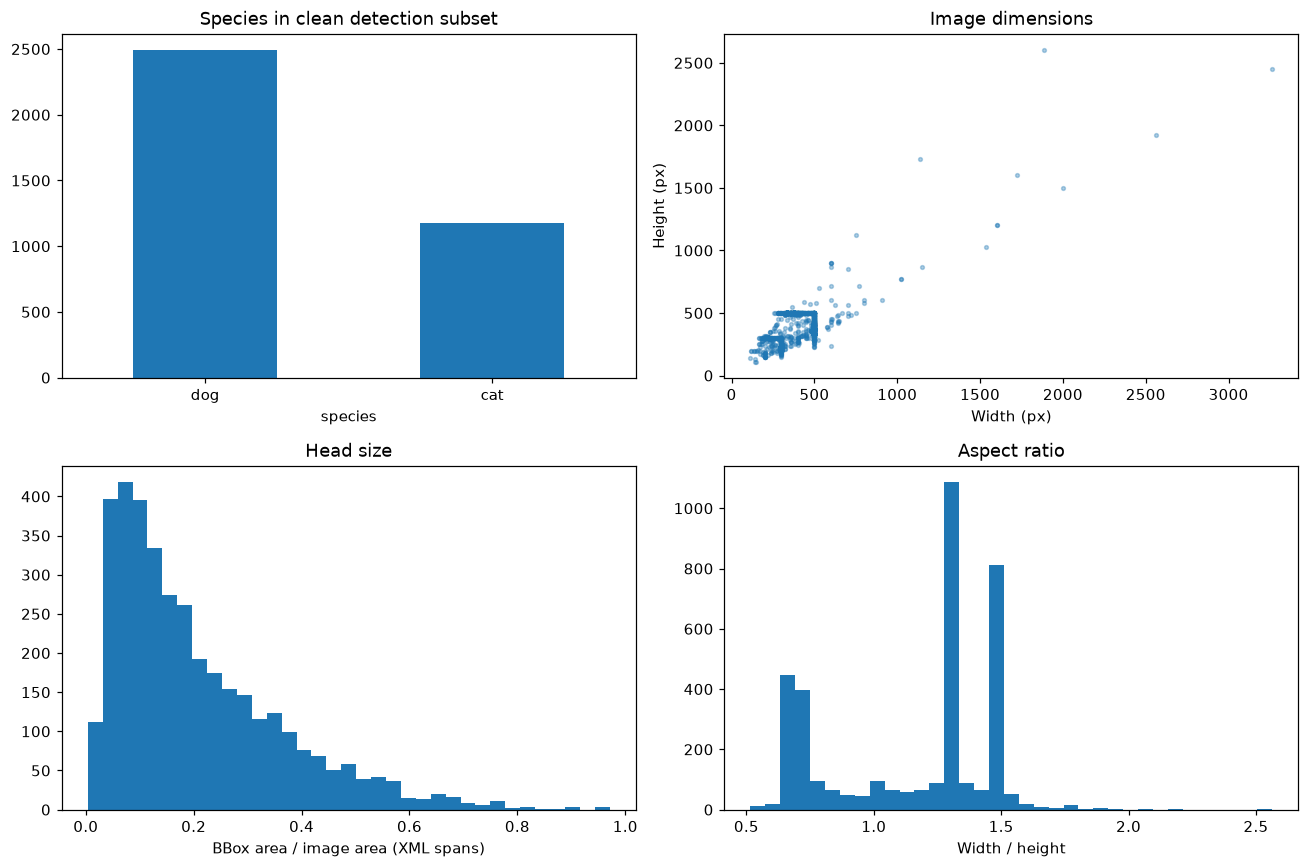

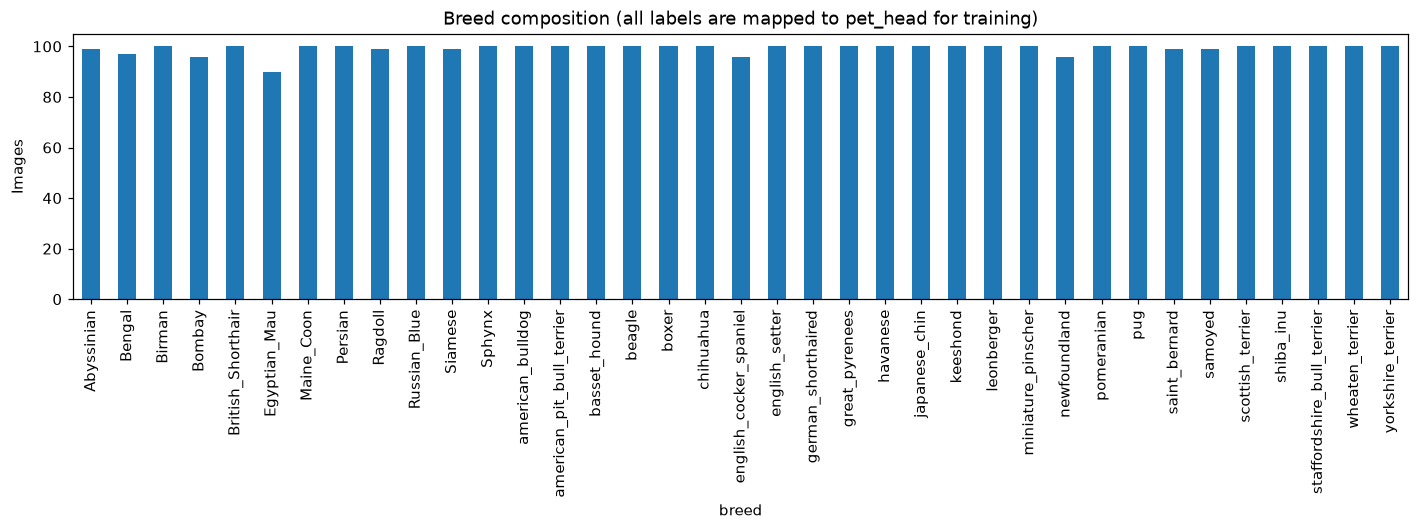

In [5]:
clean.groupby("species").size().to_csv(OUT / "species_balance.csv", header=["images"])
clean.groupby("breed").size().to_csv(OUT / "breed_balance.csv", header=["images"])
clean[["width", "height", "aspect_ratio", "bbox_area_fraction"]].describe().to_csv(
    OUT / "image_statistics.csv")
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
clean.species.value_counts().plot.bar(ax=axes[0, 0], rot=0)
axes[0, 0].set_title("Species in clean detection subset")
axes[0, 1].scatter(clean.width, clean.height, s=6, alpha=0.35)
axes[0, 1].set(xlabel="Width (px)", ylabel="Height (px)", title="Image dimensions")
axes[1, 0].hist(clean.bbox_area_fraction, bins=35)
axes[1, 0].set(xlabel="BBox area / image area (XML spans)", title="Head size")
axes[1, 1].hist(clean.aspect_ratio, bins=35)
axes[1, 1].set(xlabel="Width / height", title="Aspect ratio")
finish_figure("image_eda.png")
plt.figure(figsize=(13, 5))
clean.breed.value_counts().sort_index().plot.bar()
plt.ylabel("Images")
plt.title("Breed composition (all labels are mapped to pet_head for training)")
finish_figure("breed_balance.png")


## 5. Визуальный контроль готовых рамок

Детерминированная выборка из 12 изображений. Рамки показаны в исходных координатах.
Дополнительно выводятся четыре примера с наименьшей и наибольшей относительной
площадью головы. Проверка позволяет оценить положение рамок и выявить
несоответствия, которые не обнаруживаются при проверке диапазонов координат.


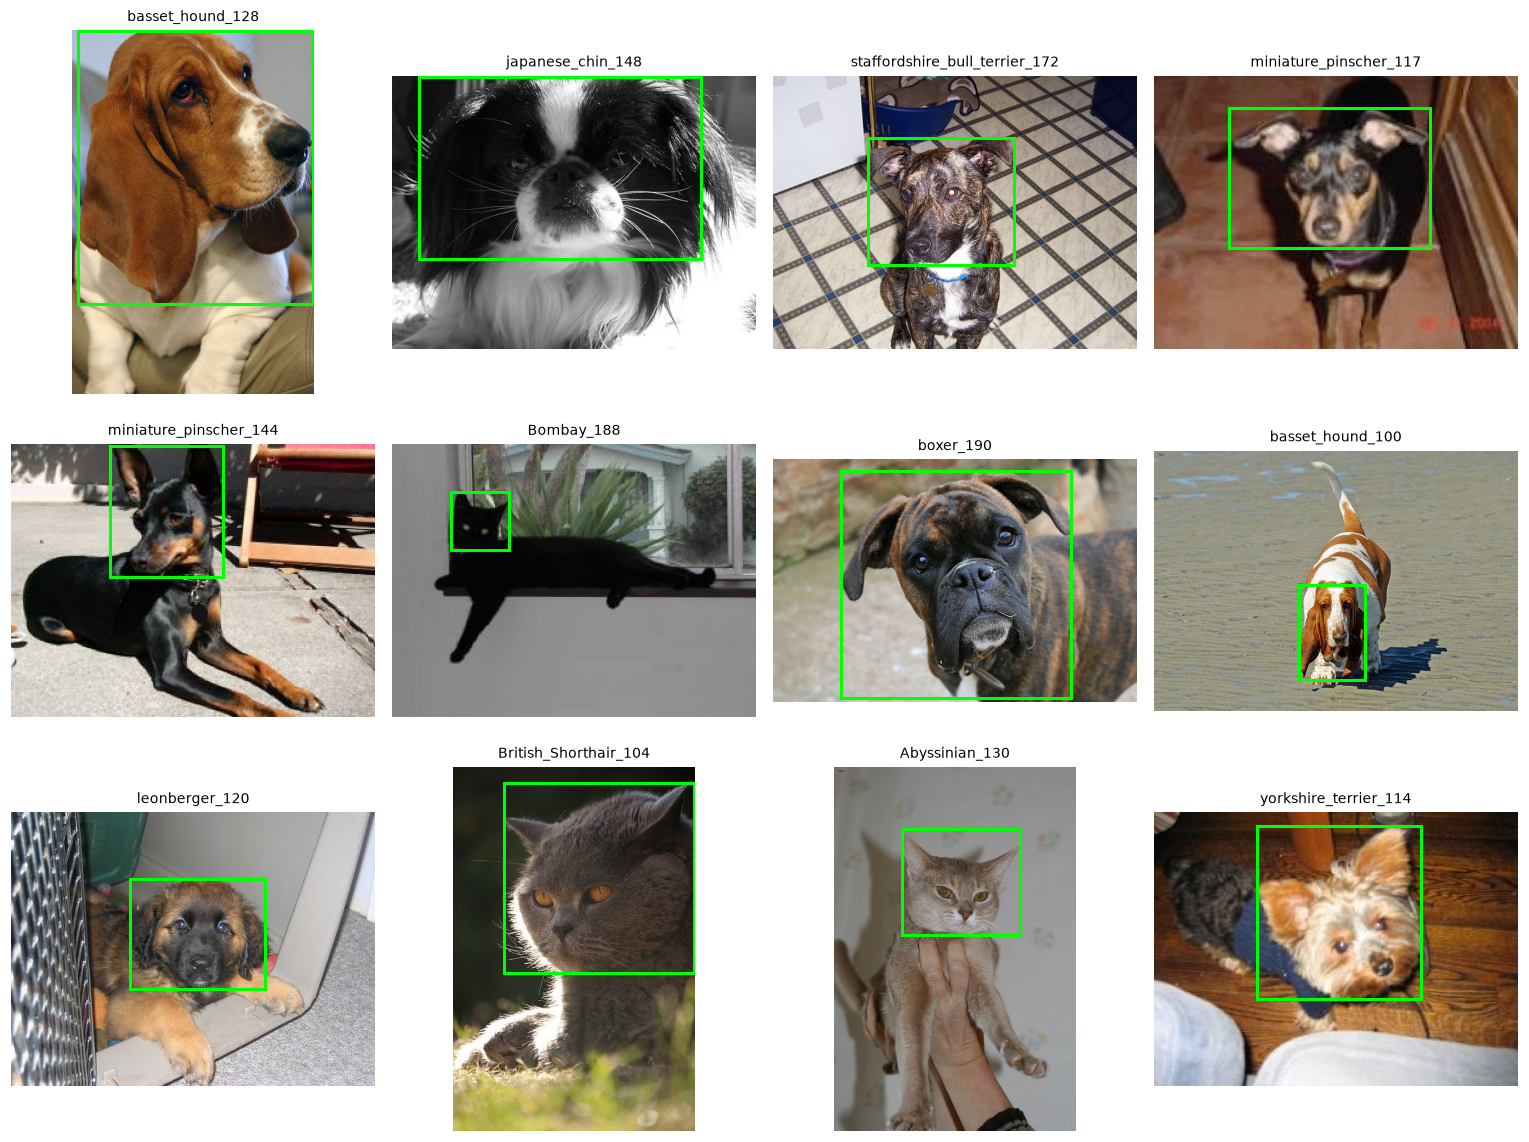

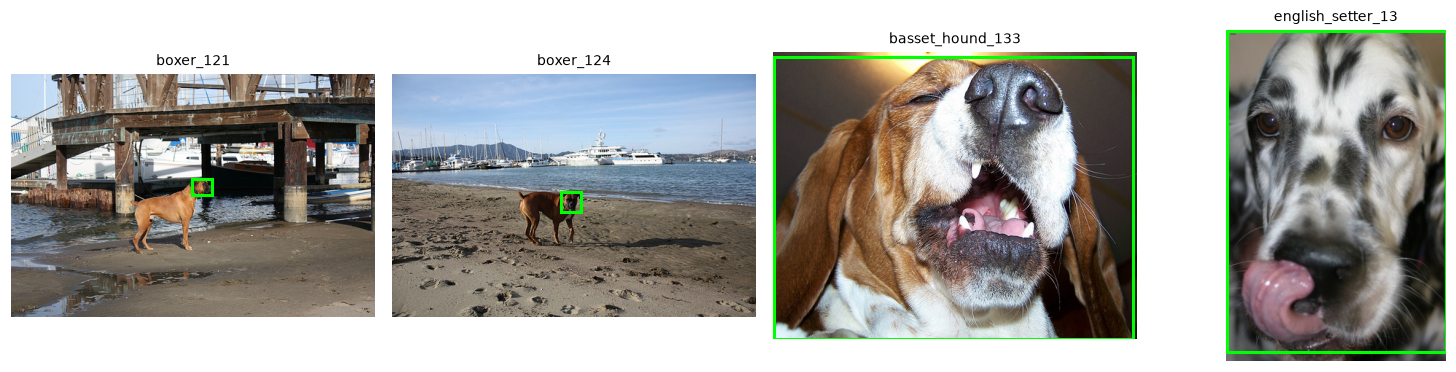

In [6]:
from matplotlib.patches import Rectangle

def plot_examples(table, filename, columns=4):
    rows = (len(table) + columns - 1) // columns
    fig, axes = plt.subplots(rows, columns, figsize=(14, 3.5 * rows), squeeze=False)
    for ax in axes.flat:
        ax.axis("off")
    for ax, row in zip(axes.flat, table.to_dict("records")):
        with Image.open(image_dir / (row["id"] + ".jpg")) as image:
            ax.imshow(image.convert("RGB"))
        ax.add_patch(Rectangle((row["xmin_xml"], row["ymin_xml"]),
            row["xmax_xml"] - row["xmin_xml"], row["ymax_xml"] - row["ymin_xml"],
            fill=False, edgecolor="lime", linewidth=2))
        ax.set_title(row["id"], fontsize=9)
    finish_figure(filename)

plot_examples(clean.sample(min(12, len(clean)), random_state=SEED), "bbox_examples.png")
extremes = pd.concat([clean.nsmallest(2, "bbox_area_fraction"),
                      clean.nlargest(2, "bbox_area_fraction")]).drop_duplicates("id")
plot_examples(extremes, "bbox_extremes.png")


## 6. Выводы


In [7]:
report = (f"В официальных списках {len(audit)} изображений; trainval: {summary['listed_trainval']}; "
          f"test: {summary['listed_test']}.\n"
          f"Читаемых изображений: {summary['readable_images']}; XML в каталоге: {summary['xml_files_in_catalog']}.\n"
          f"Рабочая выборка детекции после проверок и удаления точных копий: {len(clean)}.\n"
          f"Исключено из trainval: {len(excluded)}; причины в pet_head_excluded.csv.\n"
          f"Состав по видам: {clean.species.value_counts().to_dict()}.\n"
          "Ограничения: точный хеш не выявляет все визуальные дубликаты; автоматические проверки "
          "не заменяют визуальную оценку. Координаты сохранены в исходном соглашении XML.\n")
(OUT / "findings.txt").write_text(report, encoding="utf-8")
print(report)
provenance([{"page": "https://www.robots.ox.ac.uk/~vgg/data/pets/",
             "url": BASE, "license": "CC BY-SA 4.0",
             "citation": "Parkhi et al., Cats and Dogs, CVPR 2012"}],
           [annotation_archive, image_archive])


В официальных списках 7349 изображений; trainval: 3680; test: 3669.
Читаемых изображений: 7349; XML в каталоге: 3671.
Рабочая выборка детекции после проверок и удаления точных копий: 3670.
Исключено из trainval: 10; причины в pet_head_excluded.csv.
Состав по видам: {'dog': 2490, 'cat': 1180}.
Ограничения: точный хеш не выявляет все визуальные дубликаты; автоматические проверки не заменяют визуальную оценку. Координаты сохранены в исходном соглашении XML.

